# Comparative Evaluation of Keyword Extraction Models

## 1. Introduction

This notebook presents a comparative evaluation of four approaches to automated keyword and topic extraction: **YAKE, KeyBERT, EuroLLM, and Ministral**.

The evaluation forms part of the DDD Knowledge Management Platform project and examines the suitability of these approaches for extracting meaningful keywords and topics from Dutch- and English-language research publications.

## 2. Evaluation Objectives

The evaluation aims to:

- Compare the number and structure of generated keyword and topic suggestions.
- Examine outputs from English- and Dutch-language research documents.
- Identify observable issues such as incomplete phrases, redundancy, and generic document headings.
- Review model execution status and generation reliability.
- Identify the strengths, limitations, and suitability of each approach for further evaluation.

## 3. Methodology

The comparison uses research documents from the project's existing dataset and builds on the previously implemented extraction pipelines.

Where available, model outputs are evaluated against a common set of documents using consistent assessment criteria. Differences in input preparation, model configuration, and output format are documented to support transparent interpretation of the results.

The evaluation distinguishes between technical execution success and the semantic quality of generated suggestions. Conclusions will be based on the available evidence, with limitations explicitly identified.

## 4. Evaluation Scope

The initial analysis focuses on the development documents for which outputs from the compared approaches are available. Additional documents and evaluation results may be incorporated to strengthen the assessment.

The findings will inform the selection of a suitable keyword and topic extraction approach for the Knowledge Management Platform.

In [1]:
from pathlib import Path
import json
import pandas as pd

# Resolve the project directory
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define input paths
INVENTORY_PATH = PROJECT_ROOT / "output/inventory/documents.csv"
MANIFEST_PATH = PROJECT_ROOT / "sample_manifest.json"
KEYBERT_DIR = PROJECT_ROOT / "output/keybert"

required_files = {
    "Document inventory": INVENTORY_PATH,
    "Sample manifest": MANIFEST_PATH,
    "KeyBERT development suggestions": KEYBERT_DIR / "dev_suggestions.csv",
    "KeyBERT test suggestions": KEYBERT_DIR / "test_suggestions.csv",
}

# Verify required files
for description, path in required_files.items():
    if not path.is_file():
        raise FileNotFoundError(f"{description} not found: {path}")

# Load existing project data
inventory = pd.read_csv(INVENTORY_PATH)

with open(MANIFEST_PATH, "r", encoding="utf-8") as file:
    sample_manifest = json.load(file)

keybert_dev = pd.read_csv(KEYBERT_DIR / "dev_suggestions.csv")
keybert_test = pd.read_csv(KEYBERT_DIR / "test_suggestions.csv")

# Display dataset overview
print("Keyword Extraction Model Comparison")
print("-" * 45)
print(f"Project directory: {PROJECT_ROOT}")
print(f"Documents in inventory: {len(inventory)}")
print(f"KeyBERT development suggestions: {len(keybert_dev)}")
print(f"KeyBERT test suggestions: {len(keybert_test)}")

print("\nKeyBERT development output columns:")
print(keybert_dev.columns.tolist())

print("\nKeyBERT development output preview:")
display(keybert_dev.head())

Keyword Extraction Model Comparison
---------------------------------------------
Project directory: /Users/fatimahabbasi/Downloads/DDD
Documents in inventory: 93
KeyBERT development suggestions: 50
KeyBERT test suggestions: 60

KeyBERT development output columns:
['document_id', 'file_name', 'language', 'author_keyword_status', 'generation_mode', 'suggestion_rank', 'suggested_keyword', 'keybert_score']

KeyBERT development output preview:


,document_id,file_name,language,author_keyword_status,generation_mode,suggestion_rank,suggested_keyword,keybert_score
0,doc_5a6ef3b4929cdb64,005_building-relationships-in-higher-education...,en,verified,additional_keywords,1,students perceptions,0.6283
1,doc_5a6ef3b4929cdb64,005_building-relationships-in-higher-education...,en,verified,additional_keywords,2,contexts students,0.6143
2,doc_5a6ef3b4929cdb64,005_building-relationships-in-higher-education...,en,verified,additional_keywords,3,motivation inclass,0.6127
3,doc_5a6ef3b4929cdb64,005_building-relationships-in-higher-education...,en,verified,additional_keywords,4,perceptions student,0.5983
4,doc_5a6ef3b4929cdb64,005_building-relationships-in-higher-education...,en,verified,additional_keywords,5,motivation relationship,0.5918


In [2]:
# Identify documents shared with the YAKE, EuroLLM,
# and Ministral development experiments.

comparison_document_ids = [
    "doc_5a6ef3b4929cdb64",
    "doc_536f964e25d848c9",
]

# Select matching KeyBERT development results
keybert_comparison = keybert_dev[
    keybert_dev["document_id"].isin(comparison_document_ids)
].copy()

# Summarize available suggestions by document
comparison_overview = (
    keybert_comparison
    .groupby(
        ["document_id", "file_name", "language"],
        as_index=False
    )
    .agg(
        keybert_suggestions=("suggested_keyword", "count"),
        author_keyword_status=("author_keyword_status", "first"),
        generation_mode=("generation_mode", "first"),
    )
)

# Verify coverage
found_ids = set(comparison_overview["document_id"])
missing_ids = set(comparison_document_ids) - found_ids

print("Common Development Document Coverage")
print("-" * 45)
print(f"Documents expected: {len(comparison_document_ids)}")
print(f"Documents found in KeyBERT results: {len(found_ids)}")
print(f"Missing documents: {len(missing_ids)}")

if missing_ids:
    print(f"Missing document IDs: {sorted(missing_ids)}")

display(comparison_overview)

Common Development Document Coverage
---------------------------------------------
Documents expected: 2
Documents found in KeyBERT results: 2
Missing documents: 0


,document_id,file_name,language,keybert_suggestions,author_keyword_status,generation_mode
0,doc_536f964e25d848c9,062_leven-in-zeeland-2021.pdf,nl,10,extraction_unavailable,fallback_generation
1,doc_5a6ef3b4929cdb64,005_building-relationships-in-higher-education...,en,5,verified,additional_keywords


## 5. Model execution overview

The comparison uses saved outputs from the YAKE, EuroLLM, Ministral, and KeyBERT experiments.

The initial evaluation covers two development documents: one English and one Dutch. Execution records are inspected to establish the number of generated suggestions and identify incomplete or unsuccessful runs.

This provides an overview of model execution before assessing keyword relevance and quality.

In [3]:
import json

# Locate the notebooks containing the model experiments.
model_notebooks = {
    "YAKE": PROJECT_ROOT / "notebooks/11_keyword_topic_suggestions_input_revision.ipynb",
    "EuroLLM": PROJECT_ROOT / "notebooks/12_keyword_topic_suggestions_eurollm_numbered_output.ipynb",
    "Ministral": PROJECT_ROOT / "notebooks/13_keyword_topic_suggestions_ministral3_comparison.ipynb",
}

# Terms associated with generation summaries.
summary_terms = (
    "terms:",
    "topics:",
    "completion:",
    "parsed_at_token_limit",
    "error:",
    "review file:",
    "current run:",
)

for model_name, notebook_path in model_notebooks.items():
    print(f"\n{'=' * 60}")
    print(f"{model_name} — Saved Execution Summary")
    print("=" * 60)

    if not notebook_path.is_file():
        print("Notebook not found.")
        continue

    with open(notebook_path, "r", encoding="utf-8") as file:
        notebook = json.load(file)

    matches = []

    for cell in notebook.get("cells", []):
        if cell.get("cell_type") != "code":
            continue

        for output in cell.get("outputs", []):
            text_parts = output.get("text", [])

            if "data" in output:
                text_parts += output["data"].get("text/plain", [])

            for line in "".join(text_parts).splitlines():
                if any(term in line.lower() for term in summary_terms):
                    matches.append(line.strip())

    if matches:
        for line in matches[:20]:
            print(line[:250])
    else:
        print("No matching execution summaries found.")


YAKE — Saved Execution Summary
en 005_building-relationships-in-higher-education-to-support-student | terms: 30 | seconds: 0.14 | cached: True
nl 062_leven-in-zeeland-2021.pdf | terms: 30 | seconds: 0.14 | cached: True
en 005_building-relationships-in-higher-education-to-suppo error | topics: 0 ValueError: No valid JSON object with a topics list; inspect saved raw output.
nl 062_leven-in-zeeland-2021.pdf error | topics: 0 ValueError: No valid JSON object with a topics list; inspect saved raw output.
Review file: c:\Users\Marto Bokxa\Desktop\DDD\output\keywords\run_e26de998a8f4\keyword_review.csv
2  ValueError: No valid JSON object with a topics...
3  ValueError: No valid JSON object with a topics...
Current run: c:\Users\Marto Bokxa\Desktop\DDD\output\keywords\run_e26de998a8f4

EuroLLM — Saved Execution Summary
en 005_building-relationships-in-higher-education-to-support-student | terms: 30 | seconds: 0.15 | cached: False
nl 062_leven-in-zeeland-2021.pdf | terms: 30 | seconds: 0.18 | 

In [4]:
# Summarize recorded model outputs for the two development documents.

execution_results = pd.DataFrame([
    {"Model": "YAKE", "Language": "English", "Suggestions": 30, "Status": "Completed"},
    {"Model": "YAKE", "Language": "Dutch", "Suggestions": 30, "Status": "Completed"},
    {"Model": "KeyBERT", "Language": "English", "Suggestions": 5, "Status": "Completed"},
    {"Model": "KeyBERT", "Language": "Dutch", "Suggestions": 10, "Status": "Completed"},
    {"Model": "EuroLLM", "Language": "English", "Suggestions": 9, "Status": "Token limit reached"},
    {"Model": "EuroLLM", "Language": "Dutch", "Suggestions": 7, "Status": "Token limit reached"},
    {"Model": "Ministral", "Language": "English", "Suggestions": 20, "Status": "Completed"},
    {"Model": "Ministral", "Language": "Dutch", "Suggestions": 29, "Status": "Completed"},
])

# Present the results by model and language.
suggestion_counts = execution_results.pivot(
    index="Model",
    columns="Language",
    values="Suggestions"
)

suggestion_counts["Total"] = suggestion_counts.sum(axis=1)

display(suggestion_counts)

Language,Dutch,English,Total
Model,,,
EuroLLM,7,9,16
KeyBERT,10,5,15
Ministral,29,20,49
YAKE,30,30,60


Matplotlib is building the font cache; this may take a moment.


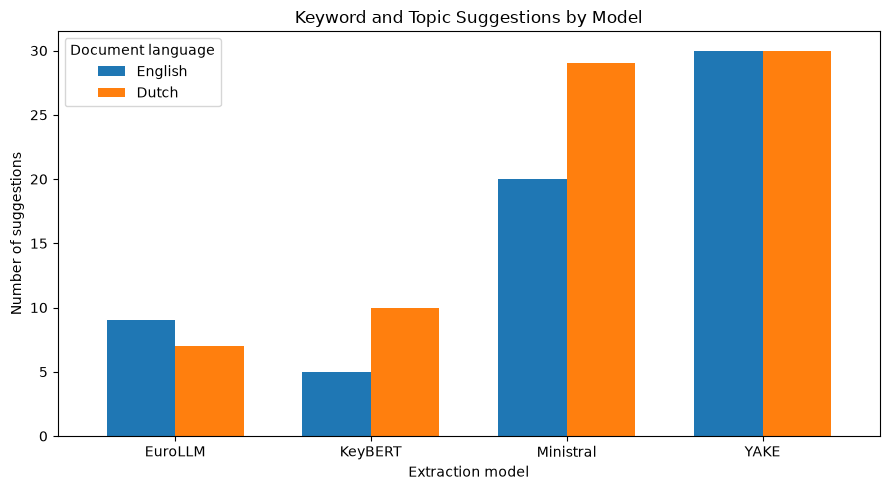

In [5]:
import matplotlib.pyplot as plt

# Compare the number of suggestions by model and language.
ax = suggestion_counts[["English", "Dutch"]].plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

ax.set_title("Keyword and Topic Suggestions by Model")
ax.set_xlabel("Extraction model")
ax.set_ylabel("Number of suggestions")
ax.legend(title="Document language")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.1 Model output distribution

The chart compares the number of keyword and topic suggestions generated by each model for one English and one Dutch research document.

YAKE produced 30 candidates for each document, while Ministral generated 20 English and 29 Dutch topics. EuroLLM returned 9 English and 7 Dutch topics before reaching its generation token limit. KeyBERT selected 5 English and 10 Dutch suggestions according to its author-keyword availability rules.

These differences reflect model configurations, output limits, and generation strategies rather than extraction quality. The relevance and usefulness of the suggestions must be evaluated separately.

## 6. Keyword quality evaluation

The number of generated suggestions does not establish their relevance or usefulness. This section examines the actual keywords and topics produced by each model.

Suggestions will be assessed for document relevance, language appropriateness, duplication, and text extraction artifacts. The evaluation will use the same criteria across models wherever comparable outputs are available.

### 6.1 KeyBERT suggestions

The following table presents KeyBERT's selected suggestions for the two development documents included in the initial comparison.

In [6]:
# Display KeyBERT suggestions for the common evaluation documents.

keybert_review = (
    keybert_comparison[
        [
            "language",
            "file_name",
            "suggestion_rank",
            "suggested_keyword"
        ]
    ]
    .sort_values(["language", "suggestion_rank"])
    .reset_index(drop=True)
)

display(keybert_review)

,language,file_name,suggestion_rank,suggested_keyword
0,en,005_building-relationships-in-higher-education...,1,students perceptions
1,en,005_building-relationships-in-higher-education...,2,contexts students
2,en,005_building-relationships-in-higher-education...,3,motivation inclass
3,en,005_building-relationships-in-higher-education...,4,perceptions student
4,en,005_building-relationships-in-higher-education...,5,motivation relationship
5,nl,062_leven-in-zeeland-2021.pdf,1,mondiale uitdagingen
6,nl,062_leven-in-zeeland-2021.pdf,2,global challenges
7,nl,062_leven-in-zeeland-2021.pdf,3,uitdagingen immers
8,nl,062_leven-in-zeeland-2021.pdf,4,uitdagingen waarvoor
9,nl,062_leven-in-zeeland-2021.pdf,5,regio uitdaging


### 6.2 Preliminary KeyBERT observations

KeyBERT generated five suggestions for the English document and ten for the Dutch document.

Initial inspection identified several limitations, including grammatically incomplete phrases, semantically overlapping suggestions, and occasional language inconsistencies.

These observations indicate that candidate selection based on semantic similarity does not necessarily produce publication-ready keywords.

### 6.3 Loading YAKE, EuroLLM, and Ministral results

The original experiment outputs are imported from the review CSV files. Each file contains ranked keyword or topic suggestions associated with document identifiers.

Because the EuroLLM and Ministral files also include YAKE baseline results, records are filtered by extraction method to prevent duplicate model entries.

In [8]:
# Load original model outputs for the comparison.

COMPARISON_DIR = PROJECT_ROOT / "output/keywords/comparison"

yake_results = pd.read_csv(COMPARISON_DIR / "yake_review.csv")
eurollm_results = pd.read_csv(COMPARISON_DIR / "eurollm_review.csv")
ministral_results = pd.read_csv(COMPARISON_DIR / "ministral_review.csv")

# Inspect method labels before filtering.
for name, df in [
    ("YAKE", yake_results),
    ("EuroLLM", eurollm_results),
    ("Ministral", ministral_results),
]:
    print(f"\n{name}")
    print(df["method"].value_counts())


YAKE
method
yake    180
Name: count, dtype: int64

EuroLLM
method
yake       60
eurollm    16
Name: count, dtype: int64

Ministral
method
yake              60
ministral_4bit    49
Name: count, dtype: int64


In [9]:
# Select model-specific suggestions for the two comparison documents.

yake_filtered = yake_results[
    (yake_results["method"] == "yake")
    & (yake_results["document_id"].isin(comparison_document_ids))
].copy()

eurollm_filtered = eurollm_results[
    (eurollm_results["method"] == "eurollm")
    & (eurollm_results["document_id"].isin(comparison_document_ids))
].copy()

ministral_filtered = ministral_results[
    (ministral_results["method"] == "ministral_4bit")
    & (ministral_results["document_id"].isin(comparison_document_ids))
].copy()

# Standardize model names.
yake_filtered["model"] = "YAKE"
eurollm_filtered["model"] = "EuroLLM"
ministral_filtered["model"] = "Ministral"

# Combine results into one table.
model_suggestions = pd.concat(
    [yake_filtered, eurollm_filtered, ministral_filtered],
    ignore_index=True
)

# Verify suggestion counts.
display(
    model_suggestions.groupby(["model", "language"])
    .size()
    .unstack(fill_value=0)
)

language,en,nl
model,,
EuroLLM,9,7
Ministral,20,29
YAKE,30,30


In [10]:
# Standardize KeyBERT results to match the other models.

keybert_standardized = keybert_comparison[
    ["document_id", "language", "suggestion_rank", "suggested_keyword"]
].copy()

keybert_standardized = keybert_standardized.rename(
    columns={
        "suggestion_rank": "rank",
        "suggested_keyword": "term"
    }
)

keybert_standardized["model"] = "KeyBERT"

# Select common columns and combine all four models.
comparison_columns = [
    "document_id", "language", "model", "rank", "term"
]

all_model_suggestions = pd.concat(
    [
        model_suggestions[comparison_columns],
        keybert_standardized[comparison_columns]
    ],
    ignore_index=True
)

# Verify the final dataset.
comparison_counts = (
    all_model_suggestions
    .groupby(["model", "language"])
    .size()
    .unstack(fill_value=0)
)

comparison_counts["Total"] = comparison_counts.sum(axis=1)

display(comparison_counts)
print("Total suggestions:", len(all_model_suggestions))

language,en,nl,Total
model,,,
EuroLLM,9,7,16
KeyBERT,5,10,15
Ministral,20,29,49
YAKE,30,30,60


Total suggestions: 140


### 6.4 Cross-model keyword comparison

The outputs of all four models have been consolidated into a common dataset containing 140 keyword and topic suggestions.

The following comparison presents the ranked suggestions for each document, allowing differences in terminology, specificity, language consistency, and redundancy to be examined.

Because the models use different generation strategies and output limits, the comparison focuses on the relevance and usefulness of individual suggestions rather than their total number.

In [11]:
# Display the top five suggestions per model for each document.

top_suggestions = (
    all_model_suggestions[
        all_model_suggestions["rank"] <= 5
    ]
    .sort_values(["language", "model", "rank"])
)

for language, language_name in [
    ("en", "English"),
    ("nl", "Dutch")
]:
    print(f"\n{language_name} document")

    comparison_table = (
        top_suggestions[
            top_suggestions["language"] == language
        ]
        .pivot(
            index="rank",
            columns="model",
            values="term"
        )
    )

    display(comparison_table)


English document


model,EuroLLM,KeyBERT,Ministral,YAKE
rank,,,,
1,Introduction,students perceptions,Student-teacher relationship quality in higher...,Connell and Wellborn
2,Methodology,contexts students,Affective commitment and intrinsic motivation,Students’ motivation
3,Results,motivation inclass,Need-supportive teaching approaches,Students’
4,Conclusion,perceptions student,Out-of-class student-staff interactions,Students’ perceptions
5,References,motivation relationship,Perceived benevolence and trust suppression ef...,motivation



Dutch document


model,EuroLLM,KeyBERT,Ministral,YAKE
rank,,,,
1,Inleiding: Inwoners over het leven op het eiland;,mondiale uitdagingen,Breed welvaartsmonitor Zeeland (CBS),Voorwoord Klimaatadaptatie
2,Aanleiding en vraagstellingen;,global challenges,Sociaal-economische structuren in Zeeland,Brede welvaart
3,Bredere welvaart; breed begrip;,uitdagingen immers,Veerkracht en crisisresilientie van gemeenscha...,Zeeland
4,Regionale Monitor Brede welvaartsontwikkeling;,uitdagingen waarvoor,Maatschappelijke basis en kwaliteit van levens...,welvaart
5,Thema's voor de 'Zeeuwse Verdieping';,regio uitdaging,Toegankelijkheid van zorg en preventieve zorgs...,Brede


### 6.5 Preliminary qualitative findings

The side-by-side comparison reveals differences in the structure and apparent usefulness of the generated suggestions.

YAKE identifies several relevant terms but also returns incomplete or overly general expressions. KeyBERT produces some conceptually relevant phrases, although grammatical inconsistencies and semantic overlap are evident.

EuroLLM frequently returns document section headings rather than substantive research topics, particularly for the English document. Ministral generates more descriptive, topic-oriented suggestions, although their relevance and factual grounding require verification against the source documents.

These findings are preliminary and based on the five highest-ranked suggestions per model for two development documents. These observations are exploratory and do not constitute a validated performance ranking.

### 6.6 Evaluation limitations

The qualitative comparison is based on direct inspection of the generated suggestions rather than manually assigned numerical quality scores.

The analysis identifies observable issues, including incomplete phrases, repeated concepts, generic document headings, and language inconsistencies. Topic relevance and factual grounding have not been independently validated against the complete source documents.

The evaluation covers two development documents, one English and one Dutch. Because the models differ in output format, selection strategy, and generation limits, the findings are exploratory and do not establish a definitive performance ranking.

## 7. Comparative Results and Discussion

The comparison of YAKE, KeyBERT, EuroLLM, and Ministral highlights differences in output structure, completeness, and apparent keyword usefulness.

| Model | Observed strengths | Observed limitations |
|---|---|---|
| YAKE | Identifies relevant terms in both English and Dutch documents without requiring an LLM | Produces incomplete expressions, generic terms, and occasional author names |
| KeyBERT | Selects a smaller set of suggestions using semantic similarity | Some suggestions contain awkward phrasing, overlapping concepts, or language inconsistencies |
| EuroLLM | Produces structured topic lists in both languages | Frequently returns document headings; generation reached the token limit for both documents |
| Ministral | Generates descriptive, topic-oriented suggestions in both languages | Some suggestions are overly detailed or potentially unsupported by the source text |

### 7.1 Interpretation

Ministral produced the most coherent and descriptive suggestions in the inspected examples, while YAKE and KeyBERT showed more frequent issues with incomplete or awkward keyword expressions. EuroLLM's outputs were dominated by document headings, limiting their usefulness for topic discovery.

However, these observations do not establish a definitive model ranking. The models were evaluated using different generation strategies, output limits, and preprocessing configurations.

The findings suggest that Ministral warrants further investigation, particularly for multilingual topic generation. A broader evaluation with consistent inputs and independently verified relevance assessments would be necessary before selecting a model for production use.

## 8. Conclusions and Recommendations

The comparison identified differences in output quality and generation reliability across YAKE, KeyBERT, EuroLLM, and Ministral.

Ministral produced the most descriptive topic suggestions in the two inspected documents, making it a promising candidate for further investigation. YAKE and KeyBERT remain useful baseline approaches, while EuroLLM's incomplete generations and emphasis on document headings indicate limitations in the tested configuration.

These findings are preliminary. The models used different preprocessing and generation strategies, and the comparison covered only one English and one Dutch document.

Before selecting a production approach, further evaluation should use a larger document sample, standardized inputs, and independently verified assessments of topic relevance and document grounding.